# Research results

Every number here comes from the JSON files in `reports/`, so this notebook runs without the dataset. The rules for the test period were fixed in `reports/test_protocol.md` before it was opened.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPORTS = Path("../reports")
INK, MUTED, BLUE, ORANGE = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#b5b4ae", "text.color": INK, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": INK, "figure.dpi": 130})


def load(name):
    return json.loads((REPORTS / name).read_text())


## How often does a fallen stock beat its sector?

Barely differently from an ordinary day. The sector return is an average pulled up by a few big winners, so even ordinary days sit below 50%.


In [2]:
summary, eda = load("features_summary.json"), load("eda.json")
rows = []
for split in ("train", "validation"):
    rows.append({"period": split, "group": "ordinary days", "beat_sector": summary["ordinary_days"][split]["beat_sector"]})
    rows.append({"period": split, "group": "all sharp falls", "beat_sector": summary[split]["base_rate"]})
    for name, item in eda[split]["news"].items():
        rows.append({"period": split, "group": name, "beat_sector": item["beat_sector"], "events": item["events"], "std_error": item["std_error"]})
pd.DataFrame(rows).pivot_table(index="group", columns="period", values="beat_sector").round(3)


period,train,validation
group,,
all sharp falls,0.460,0.449
earnings_8k,0.444,0.449
no_8k,0.470,0.463
ordinary days,0.468,0.468
other_8k,0.455,0.417
unknown,0.466,0.379


## Breakdowns on validation

Patterns differ by year and sector, and few repeat between periods. This is the error analysis behind the weak models.


In [3]:
for name in ("sector", "drop_size_bin", "vix_regime"):
    table = pd.DataFrame(eda["validation"]["breakdowns"][name]).T
    train = pd.DataFrame(eda["train"]["breakdowns"][name]).T["beat_sector"]
    display(table.assign(train_beat_sector=train)[["events", "beat_sector", "train_beat_sector"]])
pd.Series(eda["train"]["top_correlations"], name="train").to_frame().join(
    pd.Series(eda["validation"]["top_correlations"], name="validation"), how="outer").round(3)


,events,beat_sector,train_beat_sector
Basic Materials,109.0,0.4587,0.4474
Communication Services,109.0,0.4128,0.4438
Consumer Cyclical,312.0,0.4103,0.4669
Consumer Defensive,149.0,0.5101,0.4629
Energy,67.0,0.4627,0.4219
Financial Services,328.0,0.4665,0.4909
Healthcare,384.0,0.5026,0.4340
Industrials,410.0,0.4341,0.4650
Real Estate,97.0,0.4021,0.4699
Technology,426.0,0.4671,0.4646


,events,beat_sector,train_beat_sector
10_to_15,178.0,0.3764,0.4609
3_to_6,1624.0,0.4667,0.4604
6_to_10,594.0,0.4343,0.4547
over_15,118.0,0.3898,0.4950


,events,beat_sector,train_beat_sector
calm,1028.0,0.4504,0.4619
high,415.0,0.4193,0.4703
normal,1060.0,0.4632,0.4604


,train,validation
bamlh0a0hym2,NaN,0.036
close_location,NaN,-0.038
dff,0.034,0.038
dgs10,0.030,NaN
dgs2,0.038,NaN
dist_sma_200,NaN,0.025
dist_sma_50,NaN,0.026
events_past_252,0.034,NaN
has_8k_2d,-0.024,NaN
has_earnings_2d,-0.023,NaN


## Models

Twenty candidates at 30 sessions and forty at 5 and 10 sessions stayed near an AUC of 0.5, so tuning stopped as declared.


In [4]:
models, horizons = load("models.json"), load("horizon_check.json")
rows = [{"horizon": 30, **item} for item in models["best_per_family"]]
for horizon, item in horizons.items():
    rows += [{"horizon": int(horizon), **best} for best in item["best_per_family"]]
pd.DataFrame(rows)[["horizon", "family", "validation_auc", "top_precision", "top_median_rel_growth"]].sort_values(["horizon", "validation_auc"], ascending=[True, False])


,horizon,family,validation_auc,top_precision,top_median_rel_growth
4,5,xgboost,0.5223,0.4900,0.9991
5,5,forest,0.5110,0.4821,0.9991
6,5,tree,0.5034,0.5139,1.0027
7,5,logistic,0.4765,0.4422,0.9961
8,10,xgboost,0.5165,0.4263,0.9945
9,10,forest,0.5143,0.4582,0.9964
10,10,tree,0.5130,0.4303,0.9905
11,10,logistic,0.4811,0.4183,0.9903
0,30,tree,0.5086,0.3785,0.9798
1,30,forest,0.4979,0.3386,0.9763


## Strategies against benchmarks

The frozen primary strategy `no_news` lost to both indexes in both periods. The test results for `no_news_5_positions` and `top_score` rest on 75 and 20 trades and must not be read as the strategy.


,cagr,volatility,sharpe,max_drawdown,trades
index,0.258,0.128,1.854,-0.100,NaN
equal_weight_index,0.142,0.130,1.088,-0.132,NaN
cash,0.052,0.000,245.879,0.000,NaN
news_spread,-0.015,0.068,-0.188,-0.086,NaN
all_drops,0.071,0.154,0.523,-0.174,153.0
no_news,0.120,0.170,0.752,-0.176,151.0
no_news_5_positions,0.139,0.179,0.818,-0.170,76.0
no_news_stop_15,0.077,0.167,0.525,-0.192,163.0
no_news_core_20,0.229,0.130,1.657,-0.111,151.0
top_score,0.034,0.164,0.286,-0.163,151.0


,cagr,volatility,sharpe,max_drawdown,trades
index,0.153,0.168,0.930,-0.188,NaN
equal_weight_index,0.155,0.152,1.022,-0.157,NaN
cash,0.040,0.000,199.609,0.000,NaN
news_spread,0.088,0.080,1.103,-0.074,NaN
all_drops,0.081,0.217,0.466,-0.190,150.0
no_news,0.103,0.216,0.559,-0.179,150.0
no_news_5_positions,0.264,0.276,0.983,-0.163,75.0
no_news_stop_15,0.080,0.219,0.460,-0.203,163.0
no_news_core_20,0.145,0.169,0.886,-0.180,150.0
top_score,0.191,0.173,1.094,-0.188,20.0


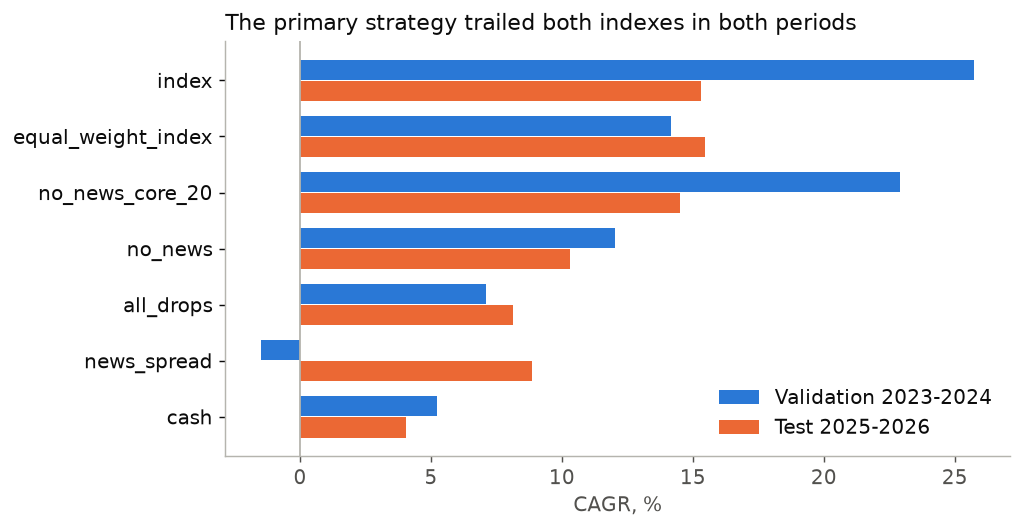

In [5]:
def strategy_table(name):
    report = load(name)
    rows = {key: report[key] for key in ("index", "equal_weight_index", "cash")}
    rows["news_spread"] = report["news_spread"]["exact"]
    rows.update({key: value["exact"] for key, value in report["strategies"].items()})
    return pd.DataFrame(rows).T[["cagr", "volatility", "sharpe", "max_drawdown", "trades"]]


validation, test = strategy_table("simulation_validation.json"), strategy_table("simulation_test.json")
display(validation.round(3), test.round(3))
order = ["index", "equal_weight_index", "no_news_core_20", "no_news", "all_drops", "news_spread", "cash"]
frame = pd.DataFrame({"Validation 2023-2024": validation["cagr"], "Test 2025-2026": test["cagr"]}).loc[order[::-1]] * 100
fig, ax = plt.subplots(figsize=(8, 4.2))
height, positions = 0.36, range(len(frame))
ax.barh([p + height / 2 + 0.01 for p in positions], frame.iloc[:, 0], height, color=BLUE, label=frame.columns[0])
ax.barh([p - height / 2 - 0.01 for p in positions], frame.iloc[:, 1], height, color=ORANGE, label=frame.columns[1])
ax.set_yticks(list(positions), frame.index)
ax.set_xlabel("CAGR, %")
ax.axvline(0, color="#b5b4ae", linewidth=1)
ax.legend(frameon=False, loc="lower right")
ax.set_title("The primary strategy trailed both indexes in both periods", loc="left", fontsize=12)
fig.tight_layout()


## AI events

AI falls did slightly better than ordinary sharp falls after 30 sessions, but the gap is within the noise of 11 overlapping events. The hand labels did not separate them as the thesis expected.


In [6]:
ai = load("ai_slice.json")
for horizon in ("30", "90"):
    print(horizon, "sessions:", ai[horizon]["all_events"], "comparison:", ai[horizon]["comparison_sharp_falls"])
    display(pd.DataFrame(ai[horizon]["by_label"]["substitutes_paid_workflow"]).T)
events = pd.DataFrame(ai["30"]["events"])
events[["event_id", "group", "stocks", "sharp_fall_stocks", "mean_rel_growth", "mean_excess_vs_index", "substitutes_paid_workflow", "product_status"]]


30 sessions: {'events': 11, 'mean': 1.0189, 'std_error': 0.0188} comparison: {'events': 2584, 'mean_rel_growth': 0.9908, 'share_beating_sector': 0.4613}


,events,mean,std_error
no,3.0,0.9902,0.0296
partly,7.0,1.0252,0.0264
yes,1.0,1.0603,NaN


90 sessions: {'events': 11, 'mean': 1.0194, 'std_error': 0.0752} comparison: {'events': 2339, 'mean_rel_growth': 0.9576, 'share_beating_sector': 0.4019}


,events,mean,std_error
no,3.0,1.0828,0.1949
partly,7.0,0.9802,0.0930
yes,1.0,1.1038,NaN


,event_id,group,stocks,sharp_fall_stocks,mean_rel_growth,mean_excess_vs_index,substitutes_paid_workflow,product_status
0,E01,Online education,2,2,1.0603,0.0024,yes,shipped
1,E02,Front-office application software,2,1,0.9090,-0.0880,partly,announced
2,E03,Gaming,4,2,0.9437,-0.0629,no,preview
3,E04,Legal technology and information services,4,4,1.1041,0.0709,partly,shipped
4,E05,Insurance brokers,5,4,1.0726,0.0377,partly,shipped
5,E06,Wealth managers,3,3,0.9581,-0.0479,partly,shipped
6,E07,Property managers and office REITs,2,2,0.9818,-0.0067,no,none
7,E08,Freight logistics,7,2,1.0655,0.0410,partly,shipped
8,E09,Cybersecurity,3,1,1.0568,0.0918,partly,preview
9,E10,IT services and legacy systems,1,True,1.0104,0.0678,partly,shipped


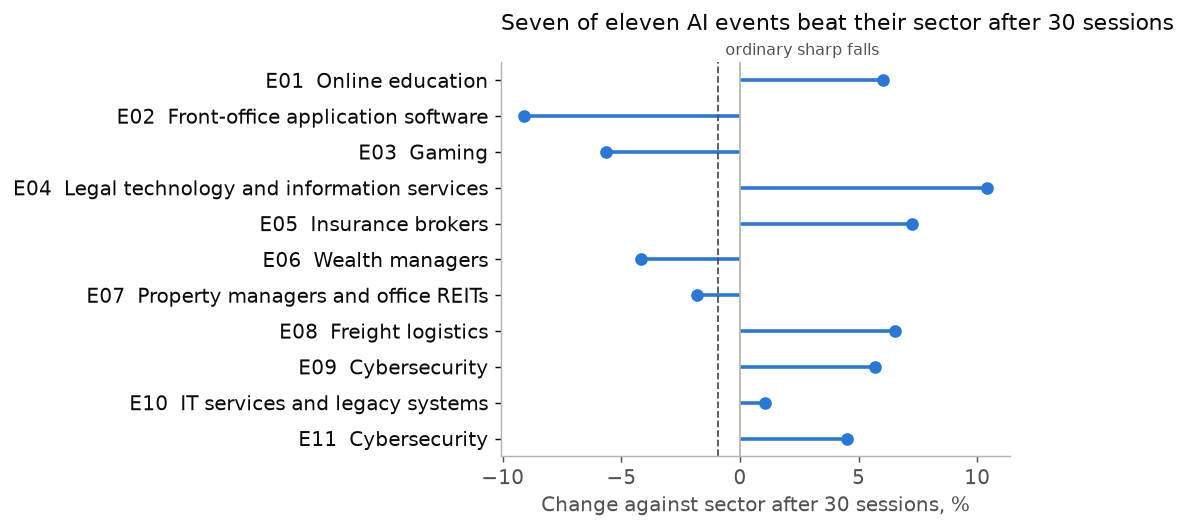

In [7]:
shown = events.assign(change=(events["mean_rel_growth"] - 1) * 100).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
labels = shown["event_id"] + "  " + shown["group"]
ax.hlines(labels, 0, shown["change"], color=BLUE, linewidth=2)
ax.scatter(shown["change"], labels, color=BLUE, s=36, zorder=3)
ax.axvline(0, color="#b5b4ae", linewidth=1)
comparison = (ai["30"]["comparison_sharp_falls"]["mean_rel_growth"] - 1) * 100
ax.axvline(comparison, color=MUTED, linewidth=1, linestyle="--")
ax.annotate("ordinary sharp falls", (comparison, 10.6), xytext=(4, 0), textcoords="offset points", color=MUTED, fontsize=9, ha="left", va="bottom", annotation_clip=False)
ax.set_xlabel("Change against sector after 30 sessions, %")
ax.set_title("Seven of eleven AI events beat their sector after 30 sessions", loc="left", fontsize=12, pad=18)
fig.tight_layout()
